In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('C:\\New_projects\\House_ban\\data\\bengaluru_house_prices.csv')

data understanding

In [3]:
print("Dataset loaded successfully")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully
Number of rows: 13320
Number of columns: 9


In [4]:
df.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [5]:
print("Dataset shape:", df.shape)

Dataset shape: (13320, 9)


In [6]:
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['area_type', 'availability', 'location', 'size', 'society', 'total_sqft', 'bath', 'balcony', 'price']


In [7]:
print("\nData types:")
print(df.dtypes)


Data types:
area_type           str
availability        str
location            str
size                str
society             str
total_sqft          str
bath            float64
balcony         float64
price           float64
dtype: object


In [8]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  str    
 1   availability  13320 non-null  str    
 2   location      13319 non-null  str    
 3   size          13304 non-null  str    
 4   society       7818 non-null   str    
 5   total_sqft    13320 non-null  str    
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), str(6)
memory usage: 936.7 KB


In [9]:
df.isnull().sum()

area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

In [10]:
print((df.isnull().mean() * 100).sort_index())

area_type        0.000000
availability     0.000000
balcony          4.572072
bath             0.548048
location         0.007508
price            0.000000
size             0.120120
society         41.306306
total_sqft       0.000000
dtype: float64


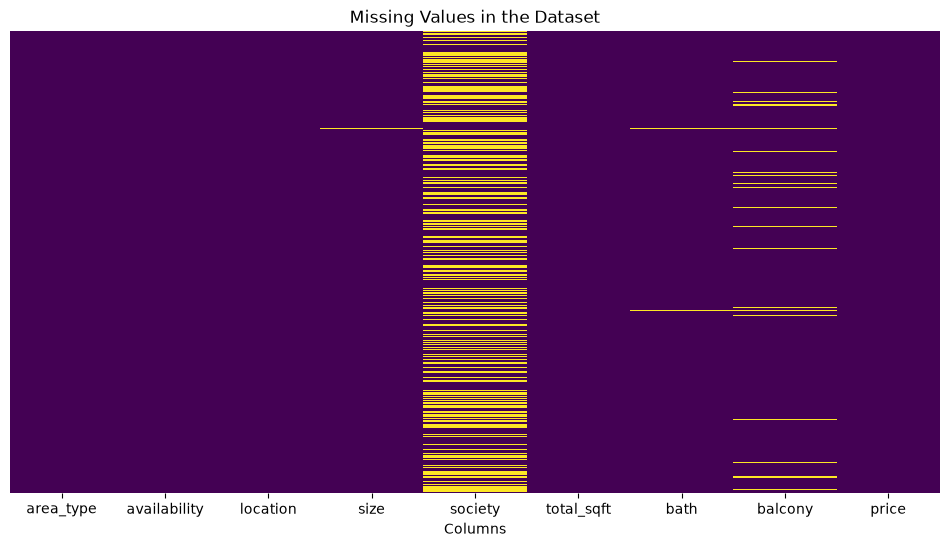

In [11]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values in the Dataset")
plt.xlabel("Columns")
plt.show()

In [12]:
print(df.duplicated().sum())

529


In [13]:
numeric_column=df.select_dtypes(include=['int64','float'])

In [14]:
numeric_column.columns.to_list()

['bath', 'balcony', 'price']

In [15]:
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_31552\58744073.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [16]:
print("Numerical columns:")
print(numeric_column)

print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
       bath  balcony   price
0       2.0      1.0   39.07
1       5.0      3.0  120.00
2       2.0      3.0   62.00
3       3.0      1.0   95.00
4       2.0      1.0   51.00
...     ...      ...     ...
13315   4.0      0.0  231.00
13316   5.0      NaN  400.00
13317   2.0      1.0   60.00
13318   4.0      1.0  488.00
13319   1.0      1.0   17.00

[13320 rows x 3 columns]

Categorical columns:
['area_type', 'availability', 'location', 'size', 'society', 'total_sqft']


In [17]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
bath,13247.0,2.692610,1.341458,1.0,2.0,2.0,3.0,40.0
balcony,12711.0,1.584376,0.817263,0.0,1.0,2.0,2.0,3.0
price,13320.0,112.565627,148.971674,8.0,50.0,72.0,120.0,3600.0


In [18]:
df.describe(include=object).T

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_31552\2435359588.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include=object).T


,count,unique,top,freq
area_type,13320,4,Super built-up Area,8790
availability,13320,81,Ready To Move,10581
location,13319,1305,Whitefield,540
size,13304,31,2 BHK,5199
society,7818,2688,GrrvaGr,80
total_sqft,13320,2117,1200,843


In [19]:
print("Zero or negative prices:", (df["price"] <= 0).sum())

for column in numeric_column:
    print(f"{column}:")
    if column not in df.columns:
        continue

    values = pd.to_numeric(df[column], errors="coerce")
    print("Infinite values:", np.isinf(values).sum())

Zero or negative prices: 0
bath:
Infinite values: 0
balcony:
Infinite values: 0
price:
Infinite values: 0


In [20]:
print("Price summary:")
print(df["price"].describe())

print("\nLowest price:", df["price"].min())
print("Highest price:", df["price"].max())
print("Average price:", df["price"].mean())
print("Median price:", df["price"].median())

Price summary:
count    13320.000000
mean       112.565627
std        148.971674
min          8.000000
25%         50.000000
50%         72.000000
75%        120.000000
max       3600.000000
Name: price, dtype: float64

Lowest price: 8.0
Highest price: 3600.0
Average price: 112.5656265015015
Median price: 72.0


In [21]:
print("========== DATASET SUMMARY ==========")
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])
print("Duplicate rows:", df.duplicated().sum())
print("Total missing values:", df.isnull().sum().sum())
print("Numeric columns:", len(numeric_column))
print("Categorical columns:", len(categorical_columns))
print("Target column: price")
print("=====================================")

========== DATASET SUMMARY ==========
Total rows: 13320
Total columns: 9
Duplicate rows: 529
Total missing values: 6201
Numeric columns: 13320
Categorical columns: 6
Target column: price


Stage 3 — Exploratory Data Analysis (EDA)

Check distributions of numeric columns

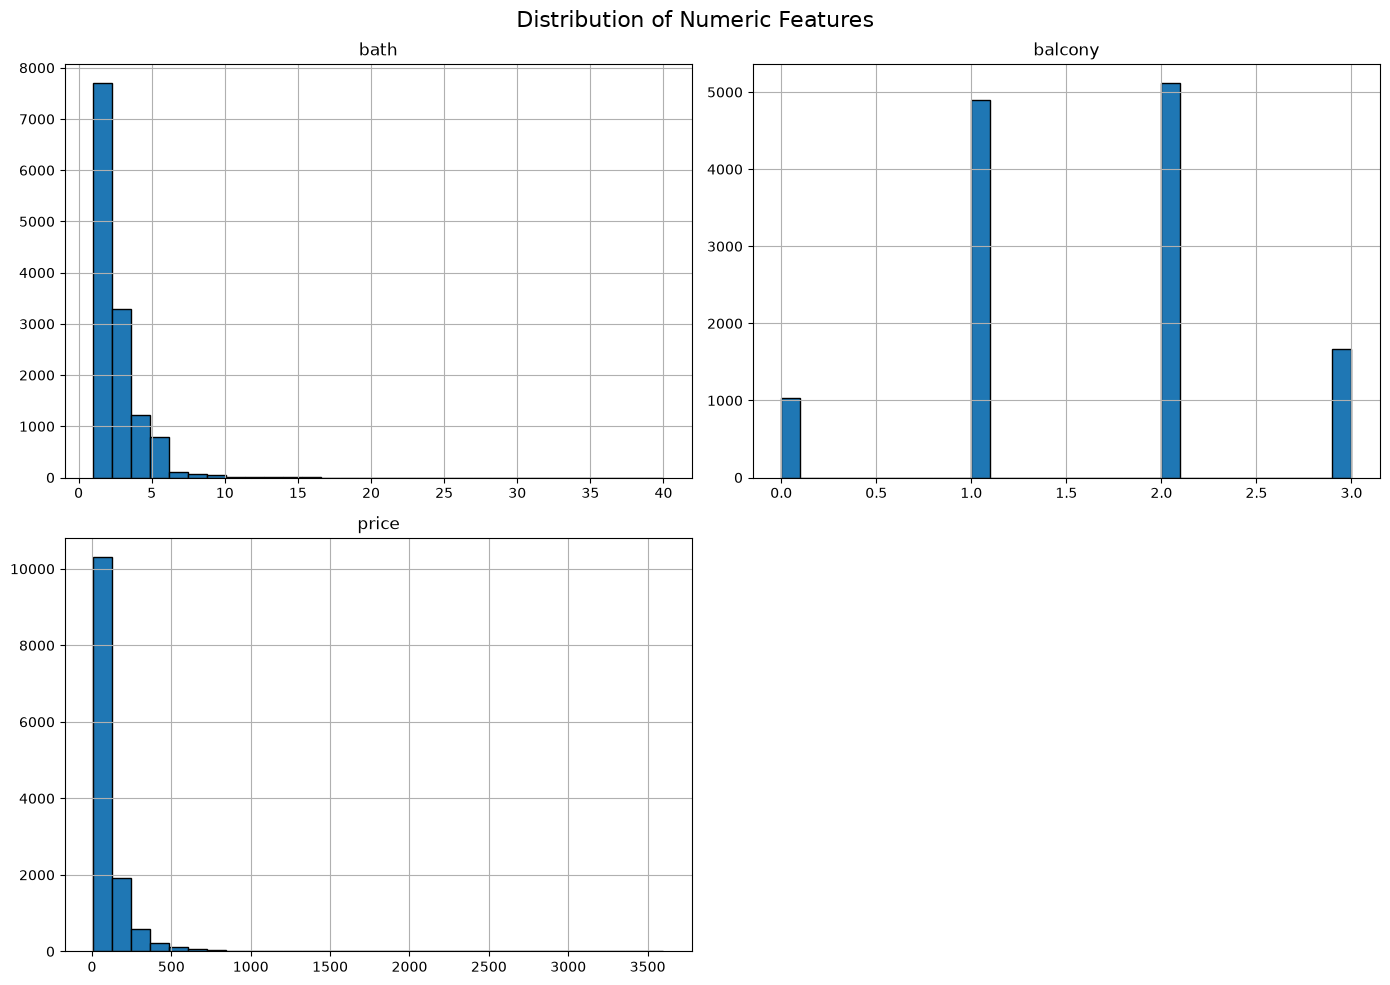

In [22]:
numeric_columns = df.select_dtypes(include="number").columns.tolist()

df[numeric_columns].hist(
    figsize=(14, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numeric Features", fontsize=16)
plt.tight_layout()
plt.show()

Analyze the house price distribution

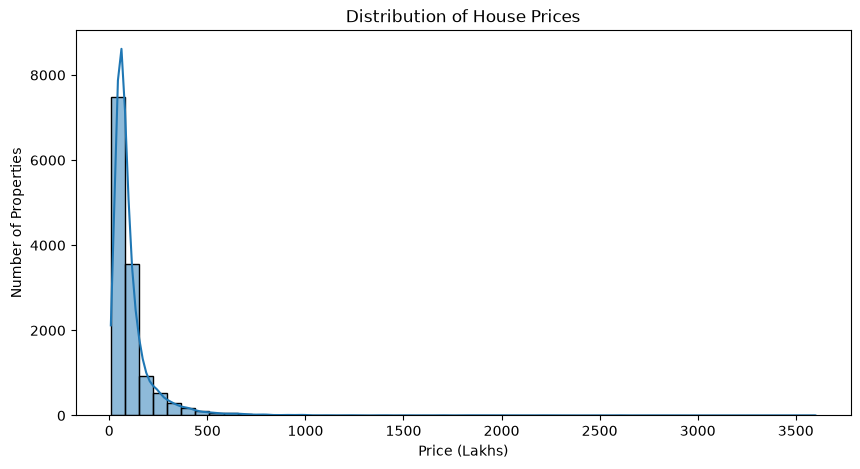

In [23]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="price", bins=50, kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("Price (Lakhs)")
plt.ylabel("Number of Properties")
plt.show()

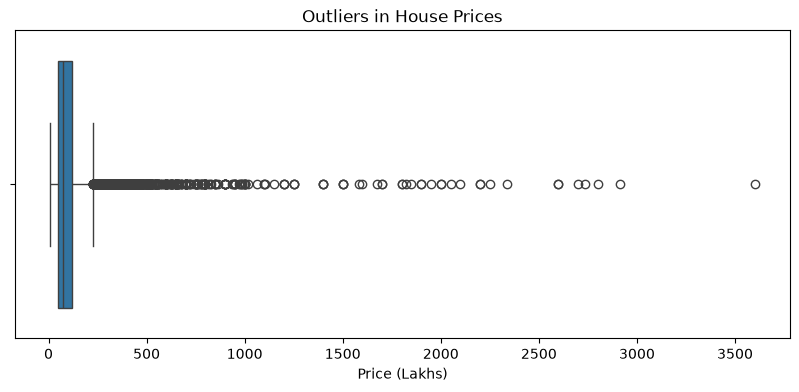

In [24]:
plt.figure(figsize=(10, 4))

sns.boxplot(data=df, x="price")

plt.title("Outliers in House Prices")
plt.xlabel("Price (Lakhs)")
plt.show()

Analyze categorical features

In [25]:
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

for column in categorical_columns:
    print(f"\nTop 10 categories in {column}")
    display(df[column].value_counts(dropna=False).head(10))


Top 10 categories in area_type


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_31552\453512834.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


area_type
Super built-up  Area    8790
Built-up  Area          2418
Plot  Area              2025
Carpet  Area              87
Name: count, dtype: int64


Top 10 categories in availability


availability
Ready To Move    10581
18-Dec             307
18-May             295
18-Apr             271
18-Aug             200
19-Dec             185
18-Jul             143
18-Mar             131
18-Jun              99
20-Dec              98
Name: count, dtype: int64

...

size
2 BHK        5199
3 BHK        4310
4 Bedroom     826
4 BHK         591
3 Bedroom     547
1 BHK         538
2 Bedroom     329
5 Bedroom     297
6 Bedroom     191
1 Bedroom     105
Name: count, dtype: int64


Top 10 categories in society


society
NaN        5502
GrrvaGr      80
PrarePa      76
Sryalan      59
Prtates      59
GMown E      56
Bhmesy       51
Prtanha      51
Prityel      50
Prarkun      49
Name: count, dtype: int64


Top 10 categories in total_sqft


total_sqft
1200    843
1100    221
1500    205
2400    196
600     180
1000    172
1350    133
1050    123
1300    117
1250    114
Name: count, dtype: int64

Plot property counts by area type

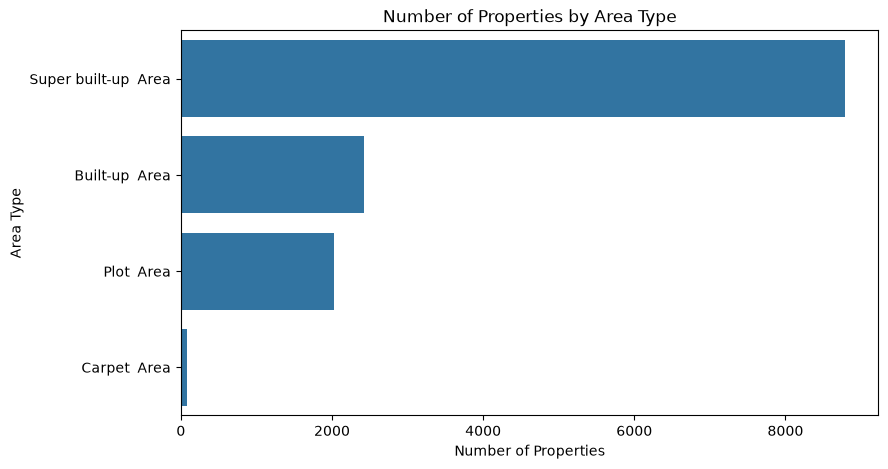

In [26]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    y="area_type",
    order=df["area_type"].value_counts().index
)

plt.title("Number of Properties by Area Type")
plt.xlabel("Number of Properties")
plt.ylabel("Area Type")
plt.show()

Analyze property locations

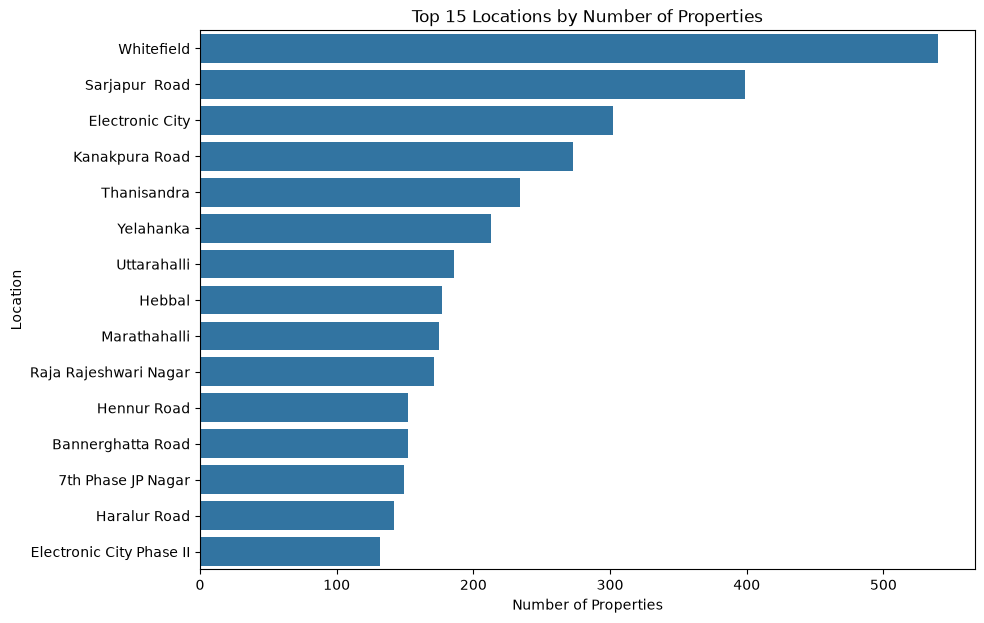

In [27]:
top_locations = df["location"].value_counts().head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    x=top_locations.values,
    y=top_locations.index
)

plt.title("Top 15 Locations by Number of Properties")
plt.xlabel("Number of Properties")
plt.ylabel("Location")
plt.show()

Compare prices by area type

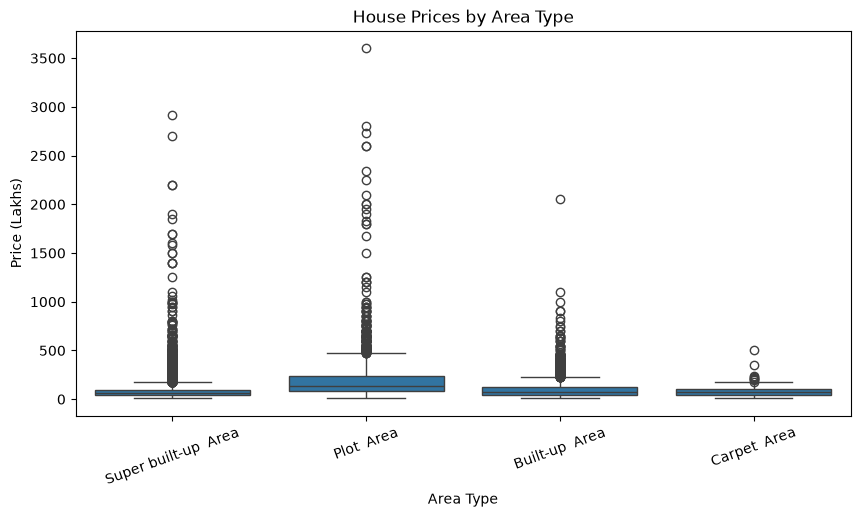

In [28]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="area_type",
    y="price"
)

plt.title("House Prices by Area Type")
plt.xlabel("Area Type")
plt.ylabel("Price (Lakhs)")
plt.xticks(rotation=20)
plt.show()

Compare prices across popular locations

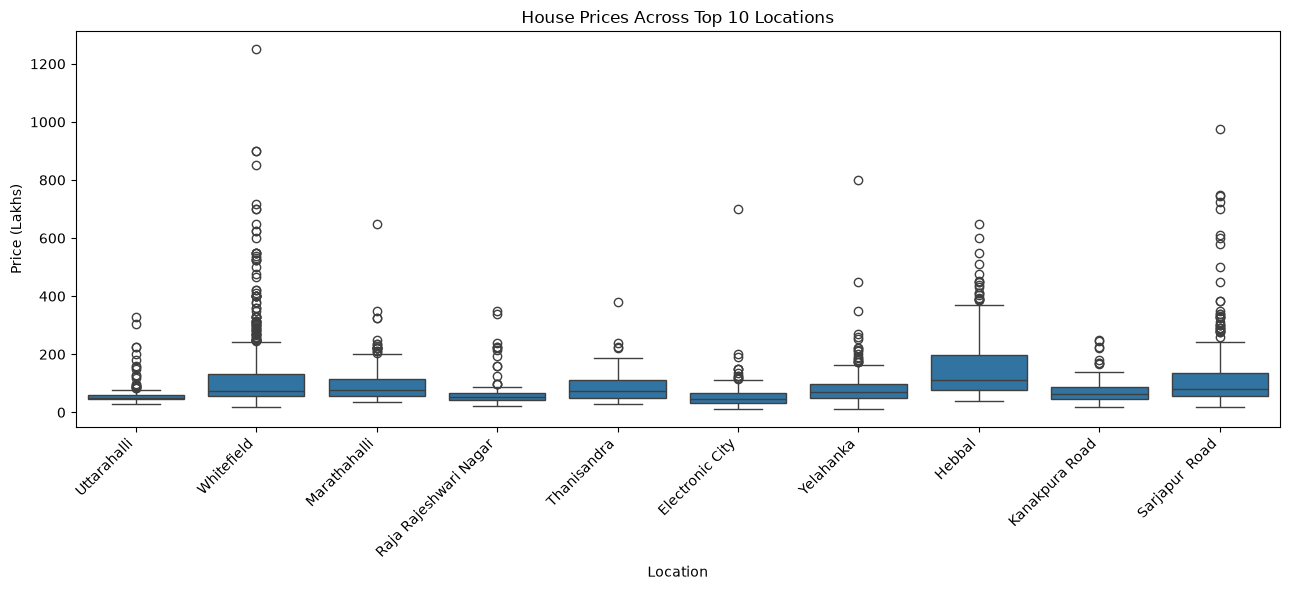

In [29]:
top_locations = df["location"].value_counts().head(10).index

location_data = df[df["location"].isin(top_locations)]

plt.figure(figsize=(13, 6))

sns.boxplot(
    data=location_data,
    x="location",
    y="price"
)

plt.title("House Prices Across Top 10 Locations")
plt.xlabel("Location")
plt.ylabel("Price (Lakhs)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Analyze price versus bathrooms

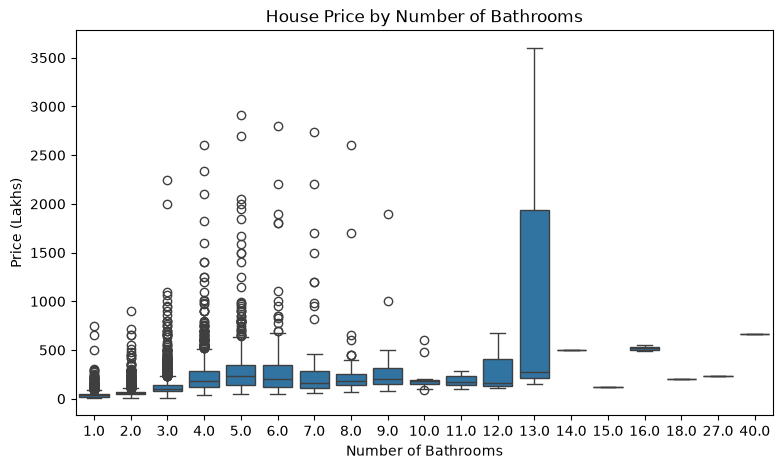

In [30]:
bath_data = df.dropna(subset=["bath", "price"])

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=bath_data,
    x="bath",
    y="price"
)

plt.title("House Price by Number of Bathrooms")
plt.xlabel("Number of Bathrooms")
plt.ylabel("Price (Lakhs)")
plt.show()

Analyze price versus total square feet

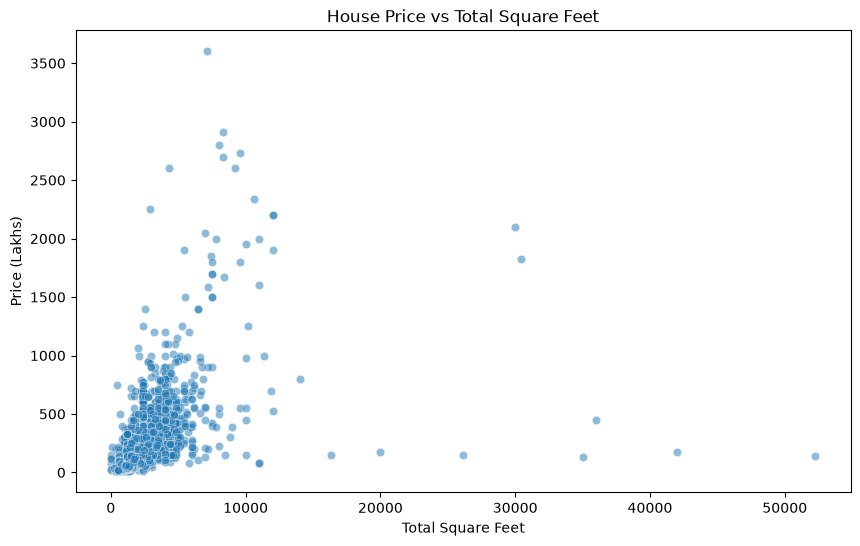

In [31]:
sqft_data = df.copy()

sqft_data["total_sqft_numeric"] = pd.to_numeric(
    sqft_data["total_sqft"],
    errors="coerce"
)

sqft_data = sqft_data.dropna(
    subset=["total_sqft_numeric", "price"]
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=sqft_data,
    x="total_sqft_numeric",
    y="price",
    alpha=0.5
)

plt.title("House Price vs Total Square Feet")
plt.xlabel("Total Square Feet")
plt.ylabel("Price (Lakhs)")
plt.show()

Check numeric correlations

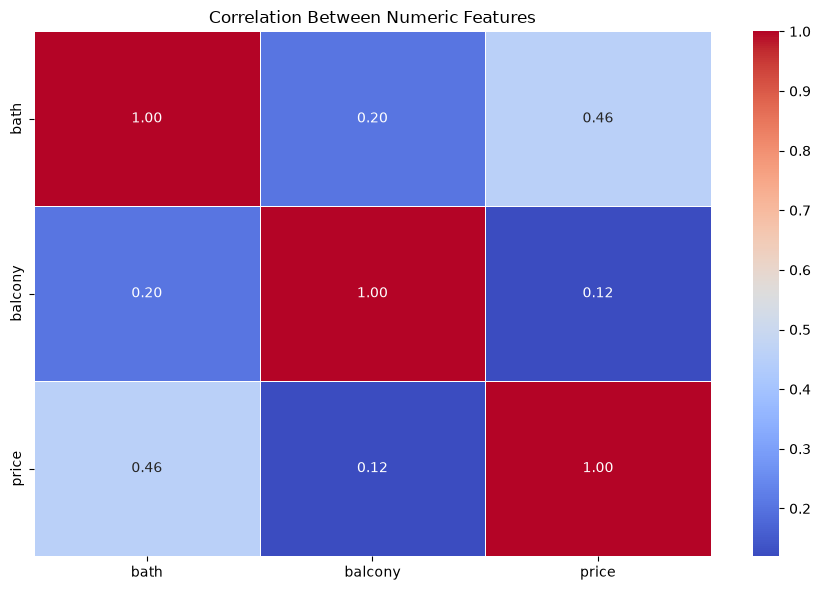

In [32]:
numeric_data = df.select_dtypes(include="number")

correlation = numeric_data.corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Numeric Features")
plt.tight_layout()
plt.show()

Compare average prices by area type

In [33]:
area_type_summary = (
    df.groupby("area_type", dropna=False)["price"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_values("median", ascending=False)
)

display(area_type_summary)

,count,mean,median,min,max
area_type,,,,,
Plot Area,2025,208.495486,140.0,8.44,3600.0
Built-up Area,2418,104.285498,70.0,9.00,2050.0
Carpet Area,87,89.502356,70.0,13.00,500.0
Super built-up Area,8790,92.971757,65.0,8.00,2912.0


Check price outliers using IQR

In [34]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["price"] < lower_bound) |
    (df["price"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Potential price outliers:", len(outliers))
print("Outlier percentage:", round(len(outliers) / len(df) * 100, 2), "%")

display(outliers.head(10))

Q1: 50.0
Q3: 120.0
IQR: 70.0
Lower bound: -55.0
Upper bound: 225.0
Potential price outliers: 1276
Outlier percentage: 9.58 %


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
7,Super built-up Area,Ready To Move,Rajaji Nagar,4 BHK,Brway G,3300,4.0,NaN,600.0
9,Plot Area,Ready To Move,Gandhi Bazar,6 Bedroom,NaN,1020,6.0,NaN,370.0
11,Plot Area,Ready To Move,Whitefield,4 Bedroom,Prrry M,2785,5.0,3.0,295.0
18,Super built-up Area,Ready To Move,Ramakrishnappa Layout,3 BHK,PeBayle,2770,4.0,2.0,290.0
22,Plot Area,Ready To Move,Thanisandra,4 Bedroom,Soitya,2800,5.0,2.0,380.0
60,Plot Area,Ready To Move,Tharabanahalli,3 Bedroom,NaN,4395,3.0,2.0,240.0
62,Plot Area,Ready To Move,Whitefield,4 Bedroom,Chranya,5700,5.0,3.0,650.0
79,Built-up Area,Ready To Move,ISRO Layout,6 Bedroom,NaN,4400,6.0,3.0,250.0
96,Plot Area,Ready To Move,Kengeri,4 Bedroom,Goardth,2894,4.0,1.0,245.0
107,Built-up Area,Ready To Move,Rajaji Nagar,3 BHK,Brway G,1640,3.0,2.0,229.0


Generate an EDA summary

In [35]:
print("========== EDA SUMMARY ==========")

print("Dataset shape:", df.shape)

print("\nPrice statistics:")
print(df["price"].describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nTop 10 locations:")
print(df["location"].value_counts().head(10))

print("\nArea type counts:")
print(df["area_type"].value_counts())

print("\nPotential price outliers:", len(outliers))

print("=================================")

========== EDA SUMMARY ==========
Dataset shape: (13320, 9)

Price statistics:
count    13320.000000
mean       112.565627
std        148.971674
min          8.000000
25%         50.000000
50%         72.000000
75%        120.000000
max       3600.000000
Name: price, dtype: float64

Missing values:
area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

Top 10 locations:
location
Whitefield               540
Sarjapur  Road           399
Electronic City          302
Kanakpura Road           273
Thanisandra              234
Yelahanka                213
Uttarahalli              186
Hebbal                   177
Marathahalli             175
Raja Rajeshwari Nagar    171
Name: count, dtype: int64

Area type counts:
area_type
Super built-up  Area    8790
Built-up  Area          2418
Plot  Area              2025
Carpet  Area              87
Name: cou

Standardize column names and text values

In [36]:
df.columns = df.columns.str.strip()

text_columns = df.select_dtypes(include="object").columns

for column in text_columns:
    df[column] = df[column].str.strip()

print(df.columns.tolist())

['area_type', 'availability', 'location', 'size', 'society', 'total_sqft', 'bath', 'balcony', 'price']


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_31552\700570039.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df.select_dtypes(include="object").columns


Remove duplicate records

In [37]:
print("Duplicates before cleaning:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Duplicates after cleaning:", df.duplicated().sum())
print("Dataset shape:", df.shape)

Duplicates before cleaning: 530
Duplicates after cleaning: 0
Dataset shape: (12790, 9)


Handle missing values

In [38]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

display(missing_summary.sort_values(
    "Missing_Count",
    ascending=False
))

,Missing_Count,Missing_Percentage
society,5328,41.66
balcony,605,4.73
bath,73,0.57
size,16,0.13
location,1,0.01
area_type,0,0.00
availability,0,0.00
total_sqft,0,0.00
price,0,0.00


In [39]:
df = df.drop(columns=["society"], errors="ignore")

df = df.dropna(
    subset=["location", "size", "total_sqft", "price"]
).copy()

print("Shape after removing essential missing values:", df.shape)

Shape after removing essential missing values: (12773, 8)


Clean the size column
Convert values such as 2 BHK and 4 Bedroom into numeric bedroom counts

In [40]:
df["bhk"] = pd.to_numeric(
    df["size"].astype(str).str.extract(r"(\d+(?:\.\d+)?)")[0],
    errors="coerce"
)

df = df.dropna(subset=["bhk"]).copy()

df = df.drop(columns=["size"])

print(df["bhk"].value_counts().sort_index())

bhk
1      638
2     5244
3     4654
4     1398
5      350
6      221
7       99
8       89
9       54
10      14
11       4
12       1
13       1
14       1
16       1
18       1
19       1
27       1
43       1
Name: count, dtype: int64


Convert total_sqft to numeric values

In [41]:
import re
def convert_sqft(value):
    value = str(value).strip().lower()

    numbers = re.findall(r"\d+(?:\.\d+)?", value)

    if not numbers:
        return np.nan

    numbers = [float(number) for number in numbers]

    # Convert ranges to their average
    sqft = sum(numbers) / len(numbers)

    if "sq. meter" in value or "sq meter" in value:
        sqft *= 10.7639
    elif "sq. yard" in value or "sq yard" in value:
        sqft *= 9
    elif "acre" in value:
        sqft *= 43560
    elif "cent" in value:
        sqft *= 435.6
    elif "guntha" in value:
        sqft *= 1089
    elif "ground" in value:
        sqft *= 2400
    elif "perch" in value:
        sqft *= 272.25

    return sqft


df["total_sqft"] = df["total_sqft"].apply(convert_sqft)

print("Missing sqft after conversion:", df["total_sqft"].isnull().sum())
display(df[["total_sqft", "price"]].head())

Missing sqft after conversion: 0


,total_sqft,price
0,1056.0,39.07
1,2600.0,120.00
2,1440.0,62.00
3,1521.0,95.00
4,1200.0,51.00


Clean bath and balcony

In [42]:
df["bath"] = pd.to_numeric(df["bath"], errors="coerce")
df["balcony"] = pd.to_numeric(df["balcony"], errors="coerce")

print("Missing bath:", df["bath"].isnull().sum())
print("Missing balcony:", df["balcony"].isnull().sum())

Missing bath: 57
Missing balcony: 589


In [43]:
df["bath"] = df["bath"].fillna(df["bath"].median())
df["balcony"] = df["balcony"].fillna(df["balcony"].median())

print("Missing bath after filling:", df["bath"].isnull().sum())
print("Missing balcony after filling:", df["balcony"].isnull().sum())

Missing bath after filling: 0
Missing balcony after filling: 0


Remove invalid records

In [44]:
df = df.dropna(
    subset=["total_sqft", "price", "location"]
).copy()

df = df[
    (df["total_sqft"] > 0) &
    (df["price"] > 0) &
    (df["bhk"] > 0) &
    (df["bath"] > 0) &
    (df["balcony"] >= 0)
].copy()

print("Shape after removing invalid records:", df.shape)

Shape after removing invalid records: (12773, 8)


Check extreme property values

In [45]:
df["sqft_per_bhk"] = df["total_sqft"] / df["bhk"]

suspicious_properties = df[df["sqft_per_bhk"] < 300]

print("Potentially suspicious properties:", len(suspicious_properties))

display(
    suspicious_properties[
        ["location", "total_sqft", "bhk", "price", "sqft_per_bhk"]
    ].head(20)
)

Potentially suspicious properties: 738


,location,total_sqft,bhk,price,sqft_per_bhk
9,Gandhi Bazar,1020.0,6,370.0,170.000000
45,HSR Layout,600.0,8,200.0,75.000000
58,Murugeshpalya,1407.0,6,150.0,234.500000
68,Devarachikkanahalli,1350.0,8,85.0,168.750000
70,Double Road,500.0,3,100.0,166.666667
78,Kaval Byrasandra,460.0,2,22.0,230.000000
89,Rajaji Nagar,710.0,6,160.0,118.333333
119,Hennur Road,276.0,2,23.0,138.000000
129,Vishwapriya Layout,950.0,7,115.0,135.714286
149,Dinnur,1034.0,6,185.0,172.333333


In [46]:
df = df[df["sqft_per_bhk"] >= 300].copy()

df = df.drop(columns=["sqft_per_bhk"])

print("Shape after applying the area-per-bedroom rule:", df.shape)

Shape after applying the area-per-bedroom rule: (12035, 8)


Handle categorical columns

In [47]:
for column in ["area_type", "location", "availability"]:
    if column in df.columns:
        df[column] = df[column].astype("string").str.strip()

if "availability" in df.columns:
    df["availability"] = df["availability"].fillna("Unknown")

df = df.dropna(subset=["area_type", "location"]).copy()

print("Missing values by column:")
print(df.isnull().sum())

Missing values by column:
area_type       0
availability    0
location        0
total_sqft      0
bath            0
balcony         0
price           0
bhk             0
dtype: int64


Final validation

In [48]:
print("Dataset shape:", df.shape)
print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nNumeric summary:")
display(df.describe())

print("\nCleaned dataset sample:")
display(df.head(10))

Dataset shape: (12035, 8)

Data types:
area_type        string
availability     string
location         string
total_sqft      float64
bath            float64
balcony         float64
price           float64
bhk               int64
dtype: object

Missing values:
area_type       0
availability    0
location        0
total_sqft      0
bath            0
balcony         0
price           0
bhk             0
dtype: int64

Duplicate rows: 40

Numeric summary:


,total_sqft,bath,balcony,price,bhk
count,1.203500e+04,12035.000000,12035.000000,12035.000000,12035.000000
mean,1.995064e+03,2.573660,1.601911,113.377810,2.662484
std,1.817320e+04,1.094483,0.801971,154.727333,0.993372
min,3.000000e+02,1.000000,0.000000,9.000000,1.000000
25%,1.116000e+03,2.000000,1.000000,50.000000,2.000000
50%,1.306000e+03,2.000000,2.000000,70.000000,3.000000
75%,1.718000e+03,3.000000,2.000000,120.000000,3.000000
max,1.306800e+06,16.000000,3.000000,3600.000000,16.000000



Cleaned dataset sample:


,area_type,availability,location,total_sqft,bath,balcony,price,bhk
0,Super built-up Area,19-Dec,Electronic City Phase II,1056.0,2.0,1.0,39.07,2
1,Plot Area,Ready To Move,Chikka Tirupathi,2600.0,5.0,3.0,120.00,4
2,Built-up Area,Ready To Move,Uttarahalli,1440.0,2.0,3.0,62.00,3
3,Super built-up Area,Ready To Move,Lingadheeranahalli,1521.0,3.0,1.0,95.00,3
4,Super built-up Area,Ready To Move,Kothanur,1200.0,2.0,1.0,51.00,2
5,Super built-up Area,Ready To Move,Whitefield,1170.0,2.0,1.0,38.00,2
6,Super built-up Area,18-May,Old Airport Road,2732.0,4.0,2.0,204.00,4
7,Super built-up Area,Ready To Move,Rajaji Nagar,3300.0,4.0,2.0,600.00,4
8,Super built-up Area,Ready To Move,Marathahalli,1310.0,3.0,1.0,63.25,3
10,Super built-up Area,18-Feb,Whitefield,1800.0,2.0,2.0,70.00,3


Save the cleaned dataset

In [49]:
from pathlib import Path

output_path = Path("../data/bengaluru_house_prices_cleaned.csv")

df.to_csv(output_path, index=False)

print("Cleaned dataset saved to:", output_path)
print("Final dataset shape:", df.shape)

Cleaned dataset saved to: ..\data\bengaluru_house_prices_cleaned.csv
Final dataset shape: (12035, 8)


Feature Preparation and Train/Test Split

In [50]:
import pandas as pd
from pathlib import Path

file_path = Path("../data/bengaluru_house_prices_cleaned.csv")

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (12035, 8)


,area_type,availability,location,total_sqft,bath,balcony,price,bhk
0,Super built-up Area,19-Dec,Electronic City Phase II,1056.0,2.0,1.0,39.07,2
1,Plot Area,Ready To Move,Chikka Tirupathi,2600.0,5.0,3.0,120.00,4
2,Built-up Area,Ready To Move,Uttarahalli,1440.0,2.0,3.0,62.00,3
3,Super built-up Area,Ready To Move,Lingadheeranahalli,1521.0,3.0,1.0,95.00,3
4,Super built-up Area,Ready To Move,Kothanur,1200.0,2.0,1.0,51.00,2


Check required columns

In [51]:
required_columns = [
    "location",
    "area_type",
    "availability",
    "total_sqft",
    "bath",
    "balcony",
    "bhk",
    "price"
]

print("Missing required columns:", 
      [col for col in required_columns if col not in df.columns])

print("Missing values:")
print(df[required_columns].isnull().sum())

Missing required columns: []
Missing values:
location        0
area_type       0
availability    0
total_sqft      0
bath            0
balcony         0
bhk             0
price           0
dtype: int64


Prepare features and target

In [52]:
X = df.drop(columns=["price"])
y = df["price"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Feature shape: (12035, 7)
Target shape: (12035,)


,area_type,availability,location,total_sqft,bath,balcony,bhk
0,Super built-up Area,19-Dec,Electronic City Phase II,1056.0,2.0,1.0,2
1,Plot Area,Ready To Move,Chikka Tirupathi,2600.0,5.0,3.0,4
2,Built-up Area,Ready To Move,Uttarahalli,1440.0,2.0,3.0,3
3,Super built-up Area,Ready To Move,Lingadheeranahalli,1521.0,3.0,1.0,3
4,Super built-up Area,Ready To Move,Kothanur,1200.0,2.0,1.0,2


0     39.07
1    120.00
2     62.00
3     95.00
4     51.00
Name: price, dtype: float64

Select numeric and categorical features

In [53]:
numeric_features = [
    "total_sqft",
    "bath",
    "balcony",
    "bhk"
]

categorical_features = [
    "location",
    "area_type",
    "availability"
]

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['total_sqft', 'bath', 'balcony', 'bhk']
Categorical features: ['location', 'area_type', 'availability']


Split the dataset

In [54]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (9628, 7)
Testing features: (2407, 7)
Training target: (9628,)
Testing target: (2407,)


Verify the split

In [55]:
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("Training percentage:", round(len(X_train) / len(df) * 100, 2))
print("Testing percentage:", round(len(X_test) / len(df) * 100, 2))

print("Outliers retained in original cleaned dataset.")

Training rows: 9628
Testing rows: 2407
Training percentage: 80.0
Testing percentage: 20.0
Outliers retained in original cleaned dataset.


Save the split datasets

In [56]:
output_dir = Path("../data/splits")
output_dir.mkdir(parents=True, exist_ok=True)

X_train.to_csv(output_dir / "X_train.csv", index=False)
X_test.to_csv(output_dir / "X_test.csv", index=False)

y_train.to_csv(output_dir / "y_train.csv", index=False)
y_test.to_csv(output_dir / "y_test.csv", index=False)

print("Training and testing datasets saved.")

Training and testing datasets saved.
